In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

In [58]:
dataframe = pd.read_csv('../datasets/ram_price_prediction_dataset.csv')

dataframe.head(10)

,id,capacity_gb,clock_speed_mhz,cas_latency,release_year,warranty_years,ram_type,brand,form_factor,use_case,rgb_lighting,heatsink_included,price_usd
0,40952,32,5570.0,28,2024,5,DDR5,G.Skill,DIMM,Gaming,0.0,0,221.33
1,5772,32,5730.0,25,2022,5,DDR5,Kingston,SO-DIMM,Gaming,0.0,0,210.61
2,16578,8,5080.0,28,2024,5,DDR5,Crucial,SO-DIMM,Gaming,0.0,1,113.20
3,30602,4,5310.0,31,2022,10,DDR5,G.Skill,SO-DIMM,Gaming,NaN,0,122.01
4,33648,32,2920.0,18,2015,2,DDR4,Crucial,SO-DIMM,Server,1.0,0,141.44
5,24876,4,2690.0,25,2015,3,DDR4,Crucial,DIMM,Laptop,1.0,0,46.21
6,6655,8,2660.0,23,2017,2,DDR4,G.Skill,SO-DIMM,Gaming,0.0,1,61.28
7,48364,8,3200.0,24,2020,2,DDR4,Corsair,DIMM,Gaming,1.0,1,85.54
8,23970,16,2450.0,20,2017,2,DDR4,Corsair,DIMM,Server,0.0,1,90.35
9,10312,32,3550.0,17,2016,3,DDR4,Corsair,DIMM,Server,0.0,0,165.68


In [59]:
dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 58000 entries, 0 to 57999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 58000 non-null  int64  
 1   capacity_gb        58000 non-null  int64  
 2   clock_speed_mhz    55689 non-null  float64
 3   cas_latency        58000 non-null  int64  
 4   release_year       58000 non-null  int64  
 5   warranty_years     58000 non-null  int64  
 6   ram_type           58000 non-null  str    
 7   brand              58000 non-null  str    
 8   form_factor        58000 non-null  str    
 9   use_case           56825 non-null  str    
 10  rgb_lighting       53945 non-null  float64
 11  heatsink_included  58000 non-null  int64  
 12  price_usd          58000 non-null  float64
dtypes: float64(3), int64(6), str(4)
memory usage: 5.8 MB


In [60]:
print(dataframe.isna().sum())
print("============================")
print("Jumlah data duplikat: ",dataframe.duplicated().sum())

id                      0
capacity_gb             0
clock_speed_mhz      2311
cas_latency             0
release_year            0
warranty_years          0
ram_type                0
brand                   0
form_factor             0
use_case             1175
rgb_lighting         4055
heatsink_included       0
price_usd               0
dtype: int64
Jumlah data duplikat:  8000


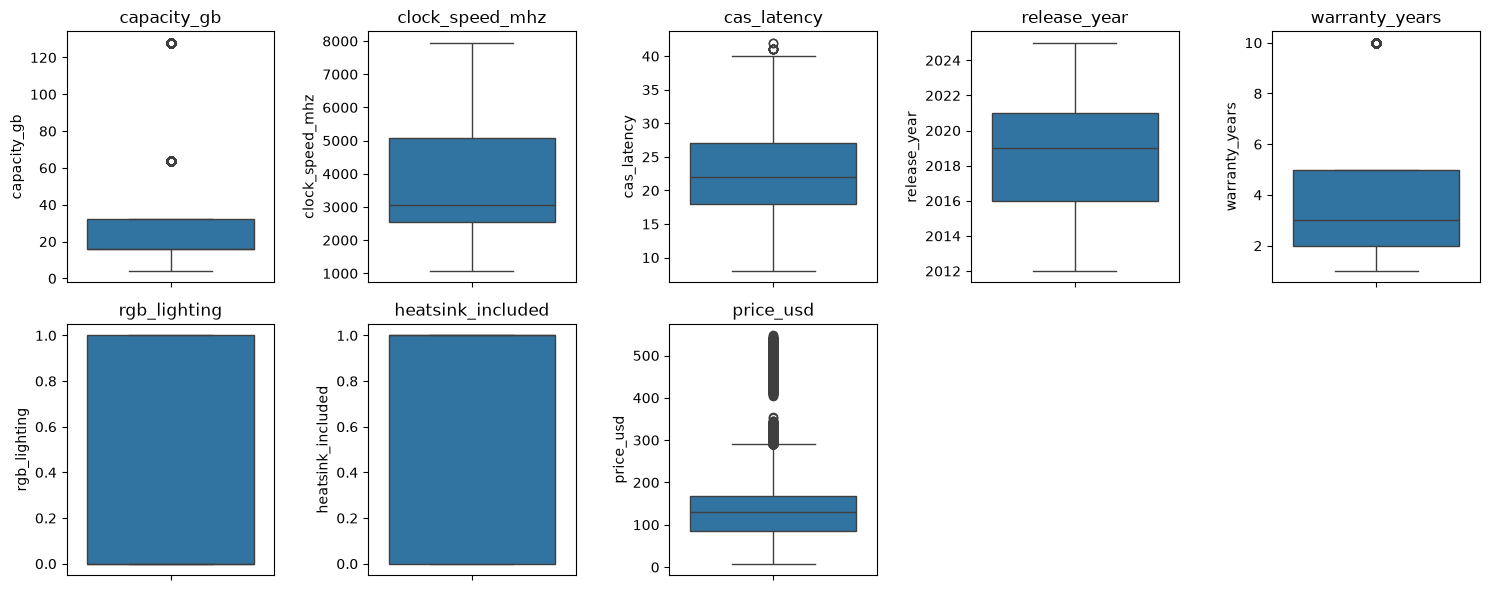

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = dataframe.select_dtypes(include="number").columns.drop(
    ["id"], errors="ignore"
)

plt.figure(figsize=(15, 6))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 5, i)
    sns.boxplot(y=dataframe[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [62]:
df_dirty = dataframe.copy()
df_cleaned = df_dirty.dropna(subset=['use_case', "rgb_lighting"])
df_cleaned = df_cleaned.drop_duplicates()

df_cleaned.info()

<class 'pandas.DataFrame'>
Index: 45580 entries, 0 to 57998
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 45580 non-null  int64  
 1   capacity_gb        45580 non-null  int64  
 2   clock_speed_mhz    43738 non-null  float64
 3   cas_latency        45580 non-null  int64  
 4   release_year       45580 non-null  int64  
 5   warranty_years     45580 non-null  int64  
 6   ram_type           45580 non-null  str    
 7   brand              45580 non-null  str    
 8   form_factor        45580 non-null  str    
 9   use_case           45580 non-null  str    
 10  rgb_lighting       45580 non-null  float64
 11  heatsink_included  45580 non-null  int64  
 12  price_usd          45580 non-null  float64
dtypes: float64(3), int64(6), str(4)
memory usage: 4.9 MB


In [63]:
for col in df_cleaned.select_dtypes(include="number").columns:
    Q1 = df_cleaned[col].quantile(0.25)
    Q3 = df_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_cleaned[(df_cleaned[col] < lower) | (df_cleaned[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")

id: 0 outliers
capacity_gb: 6913 outliers
clock_speed_mhz: 0 outliers
cas_latency: 9 outliers
release_year: 0 outliers
warranty_years: 4520 outliers
rgb_lighting: 0 outliers
heatsink_included: 0 outliers
price_usd: 2919 outliers


In [64]:
columns = [
    "capacity_gb",
    "warranty_years",
    "price_usd"
]

for col in columns:
    print(f"\n===== {col} =====")
    print(df_cleaned[col].describe())
    print("\nFrekuensi nilai:")
    print(df_cleaned[col].value_counts().sort_index().head(20))


===== capacity_gb =====
count    45580.000000
mean        27.066871
std         25.031874
min          4.000000
25%         16.000000
50%         16.000000
75%         32.000000
max        128.000000
Name: capacity_gb, dtype: float64

Frekuensi nilai:
capacity_gb
4       2243
8       9070
16     15973
32     11381
64      5507
128     1406
Name: count, dtype: int64

===== warranty_years =====
count    45580.000000
mean         3.800921
std          2.413849
min          1.000000
25%          2.000000
50%          3.000000
75%          5.000000
max         10.000000
Name: warranty_years, dtype: float64

Frekuensi nilai:
warranty_years
1      4524
2      9136
3     15875
5     11525
10     4520
Name: count, dtype: int64

===== price_usd =====
count    45580.000000
mean       145.341464
std         86.841193
min          8.000000
25%         85.850000
50%        129.295000
75%        167.852500
max        547.480000
Name: price_usd, dtype: float64

Frekuensi nilai:
price_usd
8.00     3
8

In [65]:
print(
    dataframe.groupby("capacity_gb")["price_usd"]
    .agg(["count", "mean", "median", "min", "max"])
)

             count        mean  median     min     max
capacity_gb                                           
4             2844   71.942335   62.53    8.00  159.22
8            11525   84.495949   74.89   12.08  173.55
16           20297  109.841702  100.44   32.82  203.09
32           14582  161.510679  152.13   84.43  249.96
64            6978  263.222763  253.50  185.85  354.46
128           1774  467.678309  458.76  403.79  547.48


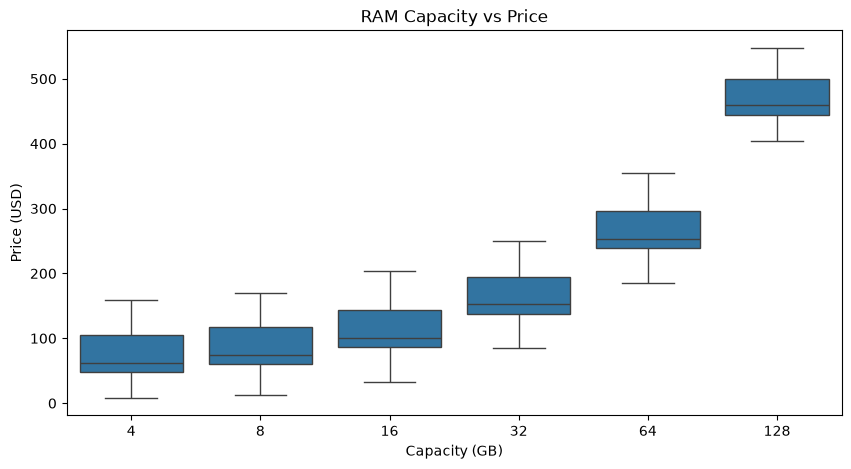

In [66]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_cleaned,
    x="capacity_gb",
    y="price_usd"
)

plt.title("RAM Capacity vs Price")
plt.xlabel("Capacity (GB)")
plt.ylabel("Price (USD)")
plt.show()

In [67]:
X = df_cleaned.drop(columns=["price_usd","id"])
y = df_cleaned['price_usd']

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

X.info()

<class 'pandas.DataFrame'>
Index: 45580 entries, 0 to 57998
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   capacity_gb        45580 non-null  int64  
 1   clock_speed_mhz    43738 non-null  float64
 2   cas_latency        45580 non-null  int64  
 3   release_year       45580 non-null  int64  
 4   warranty_years     45580 non-null  int64  
 5   ram_type           45580 non-null  str    
 6   brand              45580 non-null  str    
 7   form_factor        45580 non-null  str    
 8   use_case           45580 non-null  str    
 9   rgb_lighting       45580 non-null  float64
 10  heatsink_included  45580 non-null  int64  
dtypes: float64(2), int64(5), str(4)
memory usage: 4.2 MB


In [68]:
category_features = X.select_dtypes(include=['object']).columns.to_list()
numeric_features = X.select_dtypes(include=["number"]).columns.to_list()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
category_transformer = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

C:\Users\MyBook Z Series\AppData\Local\Temp\ipykernel_23636\4134144848.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_features = X.select_dtypes(include=['object']).columns.to_list()


In [ ]:
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", category_transformer, category_features)
])

In [ ]:
models = {
    "Linear Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]),

    "Lars": Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", linear_model.Lars())
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", GradientBoostingRegressor(random_state=42))
    ])
}

In [ ]:
def evaluate_model(model,model_name, X_test, y_test):
    y_pred = model.predict(X_test)
    results = {
        'y_pred':y_pred,
        'model':model,
        'model_name':model_name,
        'MAE': mean_absolute_error(y_test, y_pred),
        'MSE': mean_squared_error(y_test, y_pred),
        'R2': r2_score(y_test, y_pred),
    }
    return results


In [ ]:
list_results = []

for name, model in models.items():
    model.fit(x_train, y_train)

    y_pred = model.predict(x_test)
    list_results.append(evaluate_model(model,name,x_test,y_test))

In [ ]:
for results in list_results:
    print("================================================")
    print(f"Model   : {results['model_name']}")
    print(f"MAE     : {results['MAE']}")
    print(f"MSE     : {results['MSE']}")
    print(f"R2      : {results['R2']}")


Model   : Linear Regression
MAE     : 6.794180450345759
MSE     : 73.63510228883374
R2      : 0.9898885862341528
Model   : Lars
MAE     : 6.79418045034576
MSE     : 73.63510228883378
R2      : 0.9898885862341528
Model   : Gradient Boosting
MAE     : 6.609626334022084
MSE     : 67.84399157574119
R2      : 0.9906838090934111
